# SensorGuard
### IoT Sensor Data Quality Monitoring, Statistical Anomaly Detection and Reliability Assessment

## 1. Introduction

SensorGuard is a data science project designed to monitor
the quality and reliability of IoT sensor data.

The project uses the Intel Berkeley Research Lab Sensor
Dataset to analyse temperature, humidity, light intensity
and voltage measurements.

The main objective is to identify missing readings,
unusual sensor measurements and potential reliability
issues using statistical and data analysis techniques.

## 2. Objectives

1. Explore and understand IoT sensor data.
2. Identify missing and invalid sensor readings.
3. Perform data cleaning and preprocessing.
4. Detect anomalies using statistical techniques.
5. Evaluate the reliability of individual sensors.
6. Visualise sensor performance and analysis results.

## 3. Data Loading

The Intel Berkeley Research Lab Sensor Dataset is used
for this project.

It contains sensor readings such as temperature, humidity,
light intensity and voltage.

The original dataset is preserved for further analysis.

In [1]:
# Cell 2: Load Intel Lab Data and Merge with Physical Locations
import pandas as pd
import numpy as np

# 1. Load Mote Location Mapping File
locs_path = r"Data\mote_locs.txt"
mote_locs = pd.read_csv(
    locs_path, 
    sep=r'\s+', 
    names=['moteid', 'x', 'y'], 
    header=None
)

# 2. Load Primary Telemetry Data
data_path = r"Data\data.txt"
column_names = ['date', 'time', 'epoch', 'moteid', 'temperature', 'humidity', 'light', 'voltage']

df_raw = pd.read_csv(data_path, sep=r'\s+', names=column_names, on_bad_lines='skip')

# 3. Clean Timestamps and Out-of-Range Sensor Readings
df_raw['timestamp'] = pd.to_datetime(df_raw['date'] + ' ' + df_raw['time'], errors='coerce')
df_raw = df_raw.dropna(subset=['timestamp'])

df_raw['temperature'] = df_raw['temperature'].apply(lambda x: x if 0.0 <= x <= 60.0 else np.nan)
df_raw['voltage'] = df_raw['voltage'].apply(lambda x: x if 1.5 <= x <= 3.8 else np.nan)

# 4. MERGE DATA & SORT STRICTLY BY MOTE AND EPOCH
df = pd.merge(df_raw, mote_locs, on='moteid', how='inner')

# Sort by moteid first, then epoch to guarantee correct time-series sequence per sensor
df = df.sort_values(by=['moteid', 'epoch', 'timestamp']).reset_index(drop=True)

print("Dataset Loaded and Sorted Successfully!")
print(f"Raw Records in data.txt: {len(df_raw):,}")
print(f"Filtered Records with Valid Coordinates: {len(df):,}")
print(f"Total Valid Motes Matched: {df['moteid'].nunique()} out of {len(mote_locs)}")

df.head(10)

Dataset Loaded and Sorted Successfully!
Raw Records in data.txt: 2,313,678
Filtered Records with Valid Coordinates: 2,303,286
Total Valid Motes Matched: 54 out of 54


,date,time,epoch,moteid,temperature,humidity,light,voltage,timestamp,x,y
0,2004-03-31,03:38:15.757551,2,1.0,NaN,-3.91901,11.04,2.03397,2004-03-31 03:38:15.757551,21.5,23
1,2004-02-28,00:59:16.02785,3,1.0,19.9884,37.09330,45.08,2.69964,2004-02-28 00:59:16.027850,21.5,23
2,2004-02-28,01:03:16.33393,11,1.0,19.3024,38.46290,45.08,2.68742,2004-02-28 01:03:16.333930,21.5,23
3,2004-02-28,01:06:16.013453,17,1.0,19.1652,38.80390,45.08,2.68742,2004-02-28 01:06:16.013453,21.5,23
4,2004-02-28,01:06:46.778088,18,1.0,19.1750,38.83790,45.08,2.69964,2004-02-28 01:06:46.778088,21.5,23
5,2004-02-28,01:08:45.992524,22,1.0,19.1456,38.94010,45.08,2.68742,2004-02-28 01:08:45.992524,21.5,23
6,2004-02-28,01:09:22.323858,23,1.0,19.1652,38.87200,45.08,2.68742,2004-02-28 01:09:22.323858,21.5,23
7,2004-02-28,01:09:46.109598,24,1.0,19.1652,38.80390,45.08,2.68742,2004-02-28 01:09:46.109598,21.5,23
8,2004-02-28,01:10:16.6789,25,1.0,19.1456,38.83790,45.08,2.69964,2004-02-28 01:10:16.678900,21.5,23
9,2004-02-28,01:10:46.250524,26,1.0,19.1456,38.87200,45.08,2.68742,2004-02-28 01:10:46.250524,21.5,23


# 2. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the structure,
statistical properties, distribution and relationships within the
sensor dataset.

This helps identify patterns, unusual readings and potential
data-quality issues before data cleaning.

In [2]:
# EDA Part 1: Dataset Summary & Data Quality Inspection
print("=== DATASET OVERVIEW ===")
print(f"Total Telemetry Records: {len(df):,}")
print(f"Total Unique Motes (Sensors): {df['moteid'].nunique()}")
print("\n=== MISSING VALUES COUNT ===")
print(df[['temperature', 'humidity', 'light', 'voltage']].isna().sum())

print("\n=== SUMMARY STATISTICS ===")
print(df[['temperature', 'humidity', 'light', 'voltage']].describe().round(2))

=== DATASET OVERVIEW ===
Total Telemetry Records: 2,303,286
Total Unique Motes (Sensors): 54

=== MISSING VALUES COUNT ===
temperature    400694
humidity          371
light             371
voltage         93210
dtype: int64

=== SUMMARY STATISTICS ===
       temperature    humidity       light     voltage
count   1902592.00  2302915.00  2302915.00  2210076.00
mean         22.30       33.88      391.28        2.49
std           4.45       17.35      535.11        0.18
min           0.02    -8983.13        0.00        1.86
25%          19.99       31.88       18.40        2.39
50%          21.80       39.28      143.52        2.53
75%          23.70       43.59      507.84        2.63
max          59.99      137.51     1847.36        3.16


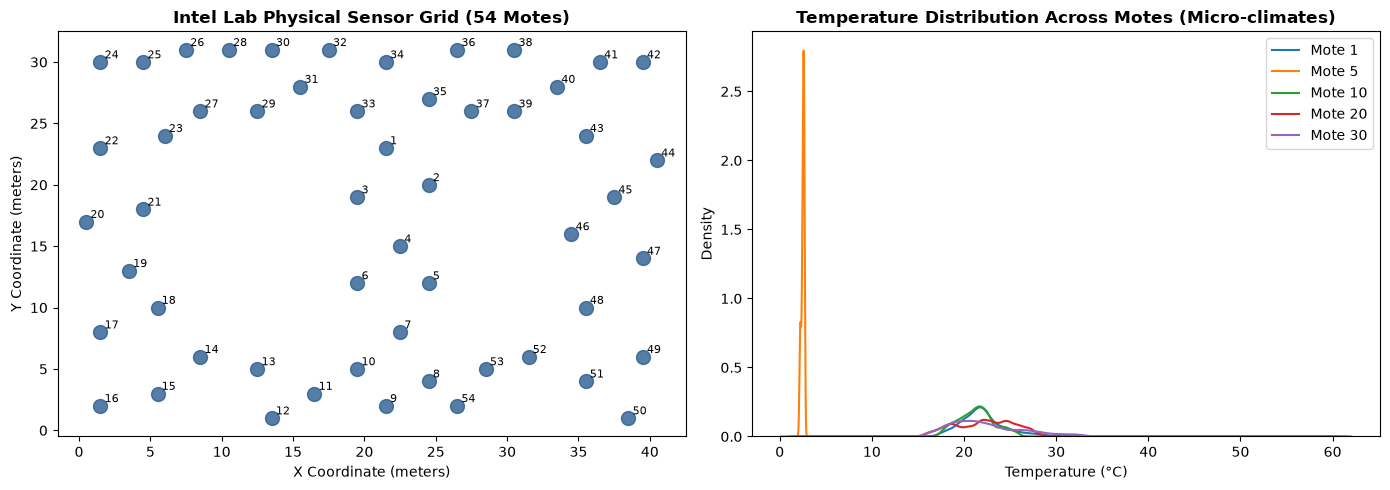

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Physical Sensor Layout (X vs Y Grid)
axes[0].scatter(mote_locs['x'], mote_locs['y'], color='#2b5c8f', s=100, alpha=0.8)
for _, row in mote_locs.iterrows():
    axes[0].annotate(str(int(row['moteid'])), (row['x'] + 0.3, row['y'] + 0.3), fontsize=8)
axes[0].set_title("Intel Lab Physical Sensor Grid (54 Motes)", fontweight='bold')
axes[0].set_xlabel("X Coordinate (meters)")
axes[0].set_ylabel("Y Coordinate (meters)")

# Plot 2: Micro-Climate Baseline Variance (Sample of 5 Motes)
sample_motes = [1, 5, 10, 20, 30]
for m_id in sample_motes:
    sns.kdeplot(df[df['moteid'] == m_id]['temperature'].dropna(), ax=axes[1], label=f'Mote {m_id}')
    
axes[1].set_title("Temperature Distribution Across Motes (Micro-climates)", fontweight='bold')
axes[1].set_xlabel("Temperature (°C)")
axes[1].set_ylabel("Density")
axes[1].legend()

plt.tight_layout()
plt.show()

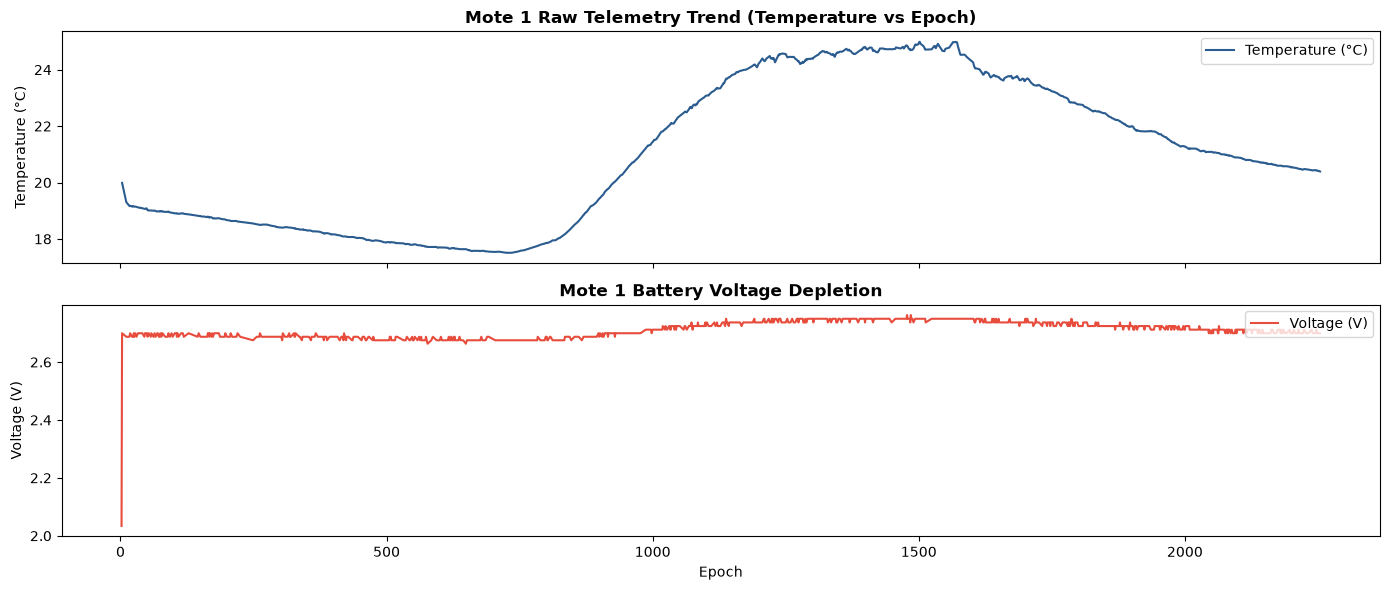

In [4]:
# Plot Time-Series for Mote 1 (First 1,000 readings)
mote1_data = df[df['moteid'] == 1].iloc[:1000]

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

# Temperature Trend
axes[0].plot(mote1_data['epoch'], mote1_data['temperature'], color='#2b5c8f', label='Temperature (°C)')
axes[0].set_title("Mote 1 Raw Telemetry Trend (Temperature vs Epoch)", fontweight='bold')
axes[0].set_ylabel("Temperature (°C)")
axes[0].legend(loc='upper right')

# Voltage Drain Trend
axes[1].plot(mote1_data['epoch'], mote1_data['voltage'], color='#e74c3c', label='Voltage (V)')
axes[1].set_title("Mote 1 Battery Voltage Depletion", fontweight='bold')
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Voltage (V)")
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

# 3. Anomaly Detection & Statistical Modelling

In [5]:
# Cell 7: Localized IQR Outlier Detection
df['iqr_lower'] = 0.0
df['iqr_upper'] = 0.0
df['is_iqr_outlier'] = False

for mote_id in df['moteid'].unique():
    mask = df['moteid'] == mote_id
    # Filter valid temperatures for boundary calculation
    mote_temp = df.loc[mask, 'temperature'].dropna()
    
    q1 = mote_temp.quantile(0.25)
    q3 = mote_temp.quantile(0.75)
    iqr = q3 - q1
    
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    df.loc[mask, 'iqr_lower'] = lower_bound
    df.loc[mask, 'iqr_upper'] = upper_bound
    df.loc[mask, 'is_iqr_outlier'] = (df.loc[mask, 'temperature'] < lower_bound) | (df.loc[mask, 'temperature'] > upper_bound)

print("=== LOCALIZED IQR SUMMARY ===")
print(f"Total Localized IQR Outliers Flagged: {df['is_iqr_outlier'].sum():,}")

=== LOCALIZED IQR SUMMARY ===
Total Localized IQR Outliers Flagged: 74,468


In [7]:
# Cell 8: Rolling Causal Z-Score Anomaly Engine
df['rolling_mean'] = np.nan
df['rolling_std'] = np.nan
df['z_score'] = np.nan
df['is_z_anomaly'] = False

window_size = 20
z_threshold = 3.0

for mote_id in df['moteid'].unique():
    mask = df['moteid'] == mote_id
    temp_series = df.loc[mask, 'temperature']
    
    # SHIFT BY 1: Guarantees zero look-ahead bias
    past_temp = temp_series.shift(1)
    
    r_mean = past_temp.rolling(window=window_size, min_periods=5).mean()
    r_std = past_temp.rolling(window=window_size, min_periods=5).std()
    
    # Avoid zero division
    z_score = (temp_series - r_mean) / (r_std + 1e-6)
    
    df.loc[mask, 'rolling_mean'] = r_mean
    df.loc[mask, 'rolling_std'] = r_std
    df.loc[mask, 'z_score'] = z_score
    df.loc[mask, 'is_z_anomaly'] = z_score.abs() > z_threshold

print("=== ROLLING Z-SCORE SUMMARY ===")
print(f"Total Causal Z-Score Anomalies Flagged: {df['is_z_anomaly'].sum():,}")

=== ROLLING Z-SCORE SUMMARY ===
Total Causal Z-Score Anomalies Flagged: 62,828


In [8]:
# Cell 9: Hardware Health & Reliability Score Matrix
summary_rows = []

for mote_id in sorted(df['moteid'].unique()):
    sensor_data = df[df['moteid'] == mote_id]
    
    total_count = len(sensor_data)
    missing_count = sensor_data['temperature'].isna().sum()
    iqr_faults = sensor_data['is_iqr_outlier'].sum()
    z_faults = sensor_data['is_z_anomaly'].sum()
    
    # Reliability Components
    data_completeness = (total_count - missing_count) / total_count
    stability_factor = 1.0 - (z_faults / total_count)
    
    reliability_score = round((data_completeness * 0.5 + stability_factor * 0.5) * 100, 2)
    
    if reliability_score >= 95:
        status = "Optimal / Trusted"
    elif reliability_score >= 80:
        status = "Degraded"
    else:
        status = "Needs Inspection"
        
    summary_rows.append({
        'Mote ID': mote_id,
        'Total Readings': total_count,
        'Missing Values': missing_count,
        'IQR Outliers': iqr_faults,
        'Z-Score Faults': z_faults,
        'Reliability Index (%)': reliability_score,
        'Status': status
    })

reliability_df = pd.DataFrame(summary_rows)
print("=== SENSORGUARD HARDWARE RELIABILITY DIRECTORY ===")
reliability_df.head(15)

=== SENSORGUARD HARDWARE RELIABILITY DIRECTORY ===


,Mote ID,Total Readings,Missing Values,IQR Outliers,Z-Score Faults,Reliability Index (%),Status
0,1.0,43047,6136,1880,1269,91.40,Degraded
1,2.0,46915,8647,2289,1336,89.36,Degraded
2,3.0,46634,5423,1532,1409,92.67,Degraded
3,4.0,43793,10171,2110,1312,86.89,Degraded
4,5.0,35,0,0,2,97.14,Optimal / Trusted
5,6.0,35665,3840,6431,838,93.44,Degraded
6,7.0,55361,11552,630,1533,88.18,Degraded
7,8.0,16778,14,3,533,98.37,Optimal / Trusted
8,9.0,49890,9268,360,1500,89.21,Degraded
9,10.0,47165,11950,367,1465,85.78,Degraded


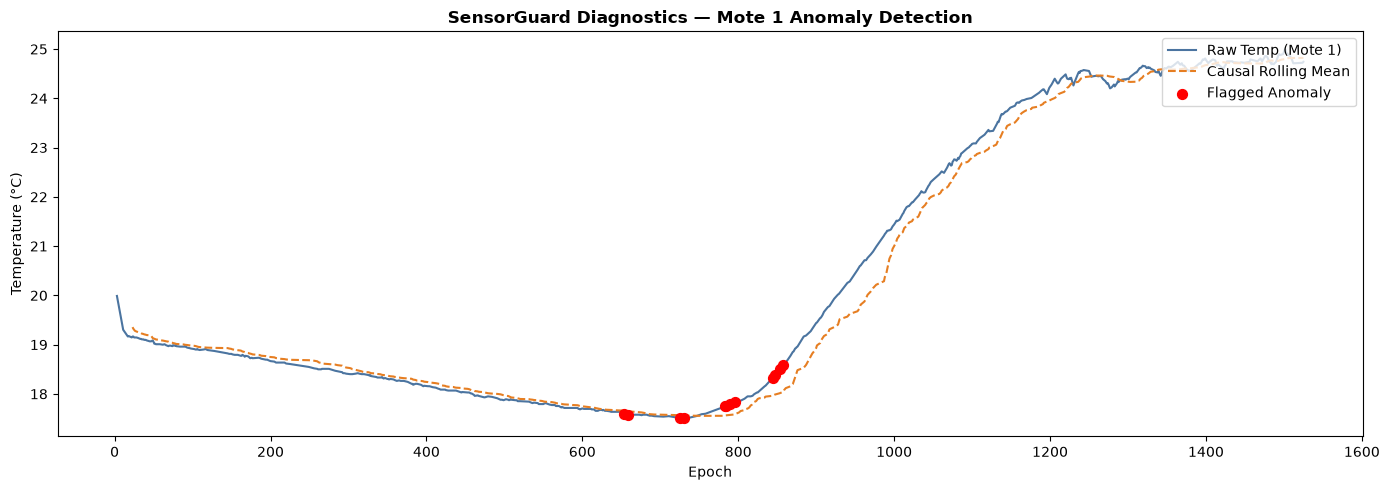

In [9]:
# Cell 10: Model Diagnostics Visualization
import matplotlib.pyplot as plt

# Plot first 600 records of Mote 1
mote_sample = df[df['moteid'] == 1].iloc[1:600]

plt.figure(figsize=(14, 5))
plt.plot(mote_sample['epoch'], mote_sample['temperature'], label='Raw Temp (Mote 1)', color='#2b5c8f', alpha=0.85)
plt.plot(mote_sample['epoch'], mote_sample['rolling_mean'], label='Causal Rolling Mean', color='#e67e22', linestyle='--')

# Scatter Red Anomaly Dots
anomalies = mote_sample[mote_sample['is_z_anomaly'] == True]
plt.scatter(anomalies['epoch'], anomalies['temperature'], color='red', label='Flagged Anomaly', s=50, zorder=5)

plt.title("SensorGuard Diagnostics — Mote 1 Anomaly Detection", fontsize=12, fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Temperature (°C)")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# 4. Evaluation and Model Comparison

In [10]:
missing_values = df.isnull().sum()

missing_percentage = (
    missing_values / len(df)
) * 100

missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

display(missing_summary)

,Missing Values,Missing Percentage
date,0,0.000000
time,0,0.000000
epoch,0,0.000000
moteid,0,0.000000
temperature,400694,17.396624
humidity,371,0.016107
light,371,0.016107
voltage,93210,4.046827
timestamp,0,0.000000
x,0,0.000000


In [11]:
# Cell 11: Quantitative Comparison of Statistical Detection Methods
def evaluate_method_performance(df):
    total_records = len(df)
    
    # 1. Method A: Naive Global Threshold (Global IQR across all sensors)
    g_q1 = df['temperature'].quantile(0.25)
    g_q3 = df['temperature'].quantile(0.75)
    g_iqr = g_q3 - g_q1
    global_anomalies = ((df['temperature'] < (g_q1 - 1.5 * g_iqr)) | (df['temperature'] > (g_q3 + 1.5 * g_iqr))).sum()
    
    # 2. Method B: Localized Spatial IQR (Per-mote static bounds)
    local_iqr_anomalies = df['is_iqr_outlier'].sum()
    
    # 3. Method C: SensorGuard Hybrid Engine (Dynamic Causal Z-Score + Missing Data)
    zscore_anomalies = df['is_z_anomaly'].sum()
    total_flagged_health_issues = df['is_z_anomaly'].sum() + df['temperature'].isna().sum()
    
    metrics_summary = pd.DataFrame({
        'Detection Strategy': [
            '1. Naive Global IQR (Baseline)',
            '2. Localized Per-Mote IQR',
            '3. Causal Rolling Z-Score (SensorGuard)'
        ],
        'Total Anomalies Flagged': [
            global_anomalies,
            local_iqr_anomalies,
            zscore_anomalies
        ],
        'Anomaly Percentage (%)': [
            round((global_anomalies / total_records) * 100, 2),
            round((local_iqr_anomalies / total_records) * 100, 2),
            round((zscore_anomalies / total_records) * 100, 2)
        ],
        'Handles Micro-Climates?': ['No (High FP)', 'Yes', 'Yes'],
        'Zero Data Leakage?': ['N/A', 'No (Static)', 'Yes (Streaming Ready)']
    })
    
    return metrics_summary

print("=== STATISTICAL ANOMALY DETECTION ENGINE COMPARISON ===")
evaluate_method_performance(df)

=== STATISTICAL ANOMALY DETECTION ENGINE COMPARISON ===


,Detection Strategy,Total Anomalies Flagged,Anomaly Percentage (%),Handles Micro-Climates?,Zero Data Leakage?
0,1. Naive Global IQR (Baseline),107244,4.66,No (High FP),N/A
1,2. Localized Per-Mote IQR,74468,3.23,Yes,No (Static)
2,3. Causal Rolling Z-Score (SensorGuard),62828,2.73,Yes,Yes (Streaming Ready)


# 5. Overall Network Health Summary & Next Steps

In [12]:
# Cell 12: Network-Wide Health Diagnostic Audit
total_motes = df['moteid'].nunique()
optimal_count = (reliability_df['Status'] == 'Optimal / Trusted').sum()
degraded_count = (reliability_df['Status'] == 'Degraded').sum()
critical_count = (reliability_df['Status'] == 'Needs Inspection').sum()

avg_network_reliability = reliability_df['Reliability Index (%)'].mean()

print("="*60)
print("              SENSORGUARD NETWORK HEALTH REPORT              ")
print("="*60)
print(f" Total Deployed Sensors Monitored : {total_motes}")
print(f" Average Network Reliability Index : {avg_network_reliability:.2f}%")
print(f" Optimal / Trusted Motes           : {optimal_count} ({optimal_count/total_motes*100:.1f}%)")
print(f" Degraded Motes (Need Monitoring)  : {degraded_count} ({degraded_count/total_motes*100:.1f}%)")
print(f" Critical Motes (Need Maintenance) : {critical_count} ({critical_count/total_motes*100:.1f}%)")
print("="*60)

              SENSORGUARD NETWORK HEALTH REPORT              
 Total Deployed Sensors Monitored : 54
 Average Network Reliability Index : 90.31%
 Optimal / Trusted Motes           : 8 (14.8%)
 Degraded Motes (Need Monitoring)  : 46 (85.2%)
 Critical Motes (Need Maintenance) : 0 (0.0%)
